# AE3GIS vs GNS3: the platforms side by side

Both platforms ran the same labs (the campus at 25–800 hosts), the same images (pinned by digest) and the same probes, each used the official way:
- **AE3GIS:** Kathara on Docker Desktop, its containers in Docker Desktop's VM;
- **GNS3 2.2.54:** Docker nodes in the GNS3 VM (VMware Fusion on a Mac, VirtualBox on Windows).

Both VMs get the same CPUs and memory, and only one runs at a time. The procedure is in `docs/benchmarks/COMPARE.md`:
- **E0:** the platform at rest;
- **E1:** deploy, ready, hold idle and teardown per lab size, 3 rounds, with the VM restarted before each step;
- **E2:** latency, flat-out TCP and a load ladder on one 100-host lab.

**How to read it:**
- Cells and charts show **AE3GIS** in blue and **GNS3** in orange; a ratio is **GNS3 ÷ AE3GIS** (above 1: GNS3 takes more time or resources).
- **Host memory** is the VM process's footprint plus its helpers' (Activity Monitor's "Memory").
- **Lab memory** is the growth over each step's own reference, the 30 s before the deploy.
- Per-container memory isn't comparable across the VMs: Docker Desktop runs cgroup v2, the GNS3 VM cgroup v1. The VM-wide and host figures are.

In [1]:
RUNS = None  # {host: run dir}; None: each host's latest <date>-compare run
QUICK = False  # a dry run's results: sanity checks only warn

In [2]:
import warnings
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import pandas as pd

from benchlib import compare as cmp, plots
from benchlib.hosts import HOSTS

warnings.filterwarnings("ignore", category=RuntimeWarning)
plots.style()
pd.set_option("display.precision", 2)
pd.set_option("display.max_columns", 30)

R = cmp.load(paths=RUNS) if RUNS else cmp.load(quick=QUICK)
P, N, C, GB, MB = cmp.PLATFORMS, cmp.NAMES, cmp.COLORS, cmp.GB, cmp.MB
name = lambda h: HOSTS[h].name if h in HOSTS else h  # noqa: E731
assert R, "no comparison runs found"
print({h: str(r.dir.name) for h, r in R.items()})

{'m4-macbook-air': '2026-11-05-compare', 'm4max-studio-dd12-60g': '2026-11-06-compare', 'microsoft-surface-7': '2026-11-06-compare'}


In [3]:
# Sanity checks: both platforms, the same lab files and images, every planned step present.
for h, r in R.items():
    issues = cmp.sanity(r)
    for i in issues:
        print(f"{name(h)}: {i}")
    if not QUICK:
        assert not issues, (h, issues)
    print(f"{name(h)}: {'ok' if not issues else str(len(issues)) + ' issue(s)'}")

M4 MacBook Air: ok
M4 Max Mac Studio: ok
Surface Laptop 7: ok


## 1. The setups

In [4]:
rows = []
for h, r in R.items():
    for p in P:
        vm = r.s["vm"].get(p) or {}
        imgs = (vm.get("images") or {})
        rows.append({
            "host": name(h), "platform": N[p],
            "version": (vm.get("platform") or {}).get("version"),
            "VM": vm.get("os"), "kernel": vm.get("kernel"), "Docker": vm.get("docker"),
            "CPUs": vm.get("ncpu"), "memory GB": round((vm.get("mem") or 0) / GB, 1),
            "cgroup": vm.get("cgroup"), "storage": vm.get("driver"),
            "lab images": len(imgs.get("lab") or {}),
            "probe image": (imgs.get("probe") or "")[7:19],
        })
display(pd.DataFrame(rows).set_index(["host", "platform"]))

version                  VM  \
host              platform                                 
M4 MacBook Air    AE3GIS       3.1.0      Docker Desktop   
                  GNS3        2.2.54  Ubuntu 20.04.6 LTS   
M4 Max Mac Studio AE3GIS       3.1.0      Docker Desktop   
                  GNS3        2.2.54  Ubuntu 20.04.6 LTS   
Surface Laptop 7  AE3GIS       3.1.0      Docker Desktop   
                  GNS3      2.2.56.1  Ubuntu 20.04.6 LTS   

                                                      kernel  Docker  CPUs  \
host              platform                                                   
M4 MacBook Air    AE3GIS                     7.0.14-linuxkit  29.9.2     8   
                  GNS3                    5.15.0-136-generic  28.1.1     8   
M4 Max Mac Studio AE3GIS                     7.0.14-linuxkit  29.8.2    12   
                  GNS3                    5.15.0-136-generic  28.1.1    12   
Surface Laptop 7  AE3GIS    6.6.87.2-microsoft-standard-WSL2  29.9.2     8   
                  GNS3                    5.15.0-136-generic  28.1.1     8   

                            memory GB cgroup    storage  lab images  \
host              platform                                            
M4 MacBook Air    AE3GIS         15.6      2  overlayfs           0   
                  GNS3           15.6      1   overlay2           0   
M4 Max Mac Studio AE3GIS         58.8      2  overlayfs           0   
                  GNS3           58.7      1   overlay2           0   
Surface Laptop 7  AE3GIS         15.6      2  overlayfs           0   
                  GNS3           15.6      1   overlay2           0   

                           probe image  
host              platform              
M4 MacBook Air    AE3GIS                
                  GNS3                  
M4 Max Mac Studio AE3GIS                
                  GNS3                  
Surface Laptop 7  AE3GIS                
                  GNS3

## 2. E0: the platform at rest

After a VM restart, with no lab: the last 3 minutes of 5. On the host, a platform is its VM process plus its helpers (Docker Desktop's backend and services; VMware Fusion's). Inside the VM, AE3GIS's backend runs as a container.

**M4 MacBook Air**

platform,AE3GIS,GNS3,GNS3 ÷ AE3GIS
host footprint GB,2.09,2.25,1.08
VM process GB,1.64,2.23,1.36
helpers GB,0.447,0.0205,0.0459
host cores,0.045,0.0326,0.724
memory used in the VM GB,0.778,0.574,0.738
cores in the VM,0.0107,0.0114,1.07
VM disk on the host GB,46.7,36.8,0.789
VM start s,6.77,42.8,6.33
reps,3,3,1


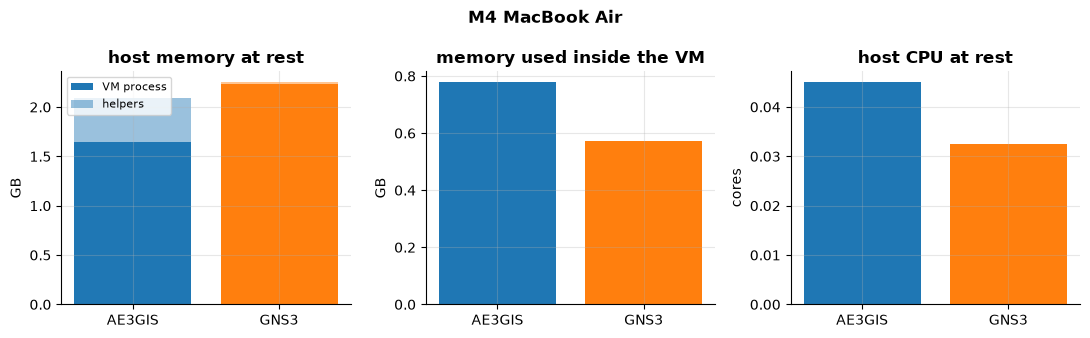

**M4 Max Mac Studio**

platform,AE3GIS,GNS3,GNS3 ÷ AE3GIS
host footprint GB,3.81,3.35,0.879
VM process GB,3.19,3.32,1.04
helpers GB,0.617,0.026,0.0422
host cores,0.0577,0.0323,0.559
memory used in the VM GB,1.13,1.02,0.905
cores in the VM,0.0169,0.0105,0.618
VM disk on the host GB,45.9,18,0.392
VM start s,9.27,72,7.77
reps,3,3,1


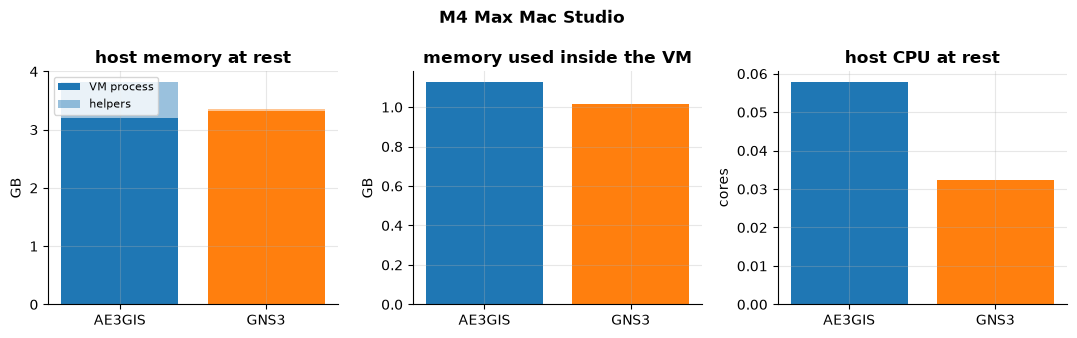

**Surface Laptop 7**

platform,AE3GIS,GNS3,GNS3 ÷ AE3GIS
host footprint GB,2.92,2.25,0.769
VM process GB,2.04,2.07,1.02
helpers GB,0.881,0.172,0.196
host cores,0.0284,0.187,6.6
memory used in the VM GB,0.784,0.724,0.923
cores in the VM,0.00903,0.0326,3.61
VM disk on the host GB,89.9,38.8,0.432
VM start s,11.7,70,5.96
reps,3,3,1


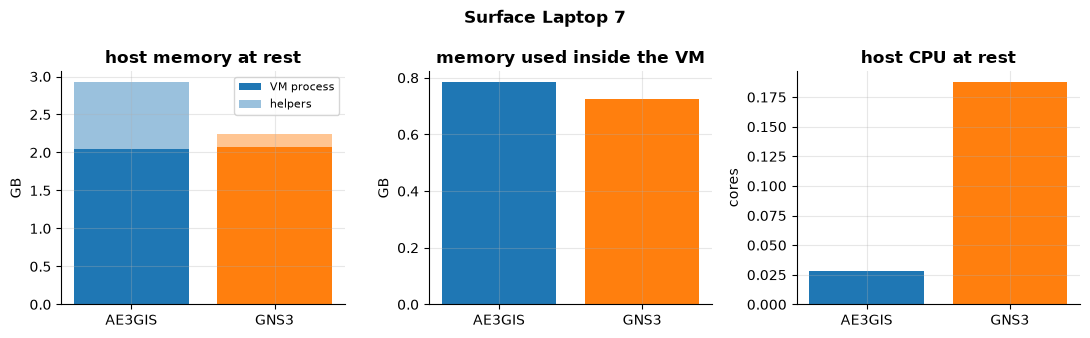

In [5]:
for h, r in R.items():
    e = r.e0.groupby("platform").mean(numeric_only=True)
    t = pd.DataFrame({
        "host footprint GB": e["host_footprint"] / GB,
        "  VM process GB": e["host_footprint_vm"] / GB,
        "  helpers GB": e["host_footprint_helpers"] / GB,
        "host cores": e["host_cores"],
        "memory used in the VM GB": e["vm_mem"] / GB,
        "cores in the VM": e["vm_cores"],
        "VM disk on the host GB": e["vm_disk"] / GB,
        "VM start s": e["vm_start_s"],
        "reps": r.e0.groupby("platform").size(),
    }).rename(index=N).T
    if {"AE3GIS", "GNS3"} <= set(t.columns):
        t["GNS3 ÷ AE3GIS"] = t["GNS3"] / t["AE3GIS"]
    display(Markdown(f"**{name(h)}**"))
    display(t.style.format("{:.3g}"))

    fig, ax = plt.subplots(1, 3, figsize=(11, 3.4))
    x = range(len(e))
    labels = [N[p] for p in e.index]
    ax[0].bar(x, e["host_footprint_vm"] / GB, color=[C[p] for p in e.index], label="VM process")
    ax[0].bar(x, e["host_footprint_helpers"] / GB, bottom=e["host_footprint_vm"] / GB,
              color=[C[p] for p in e.index], alpha=0.45, label="helpers")
    ax[0].set(title="host memory at rest", ylabel="GB", xticks=list(x), xticklabels=labels)
    ax[0].legend(fontsize=8)
    ax[1].bar(x, e["vm_mem"] / GB, color=[C[p] for p in e.index])
    ax[1].set(title="memory used inside the VM", ylabel="GB", xticks=list(x), xticklabels=labels)
    ax[2].bar(x, e["host_cores"], color=[C[p] for p in e.index])
    ax[2].set(title="host CPU at rest", ylabel="cores", xticks=list(x), xticklabels=labels)
    fig.suptitle(name(h), fontweight="bold")
    fig.tight_layout()
    plt.show()

In [6]:
# The platforms' own processes inside the VM at rest (RSS; shared pages count in each).
for h, r in R.items():
    if len(r.e0_infra):
        t = r.e0_infra.pivot(index="process", columns="platform", values="rss").rename(columns=N) / MB
        display(Markdown(f"**{name(h)}**, MB"))
        display(t.style.format("{:.0f}", na_rep="–"))

**M4 MacBook Air**, MB

platform,AE3GIS,GNS3
process,,
containerd,108,41
containerd-shim,55,13
dockerd,128,83
gns3server,–,50


**M4 Max Mac Studio**, MB

platform,AE3GIS,GNS3
process,,
containerd,135,41
containerd-shim,43,13
dockerd,113,125
gns3server,–,53


**Surface Laptop 7**, MB

platform,AE3GIS,GNS3
process,,
containerd,73,50
containerd-shim,31,13
dockerd,107,149
gns3server,–,53


## 3. E1: how fast a lab is up and gone

- **deploy:** from the request until the platform reports every node started;
- **ready:** until every readiness ping (each host to its gateway and to a server, across the core) answers;
- **usable** = deploy + ready;
- **teardown:** until the lab's containers are gone.

Lines are the mean of the reps that finished, bars the range. A size that failed, was capped (45 min) or skipped shows in the table below the chart.

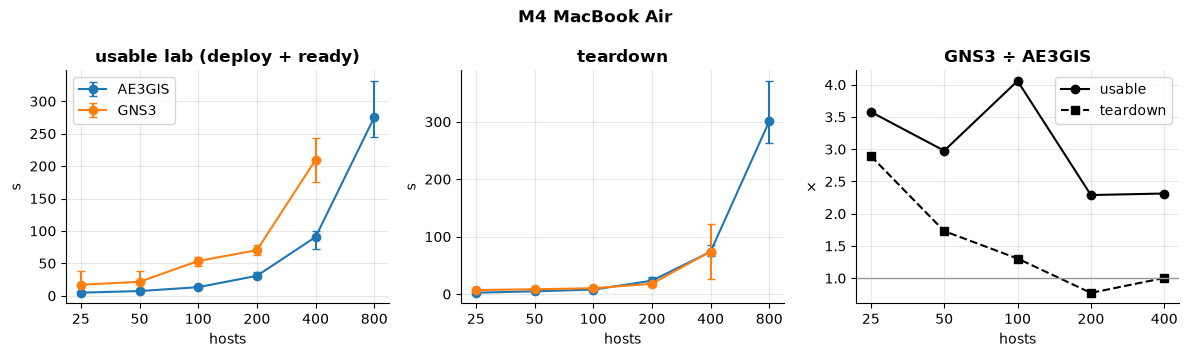

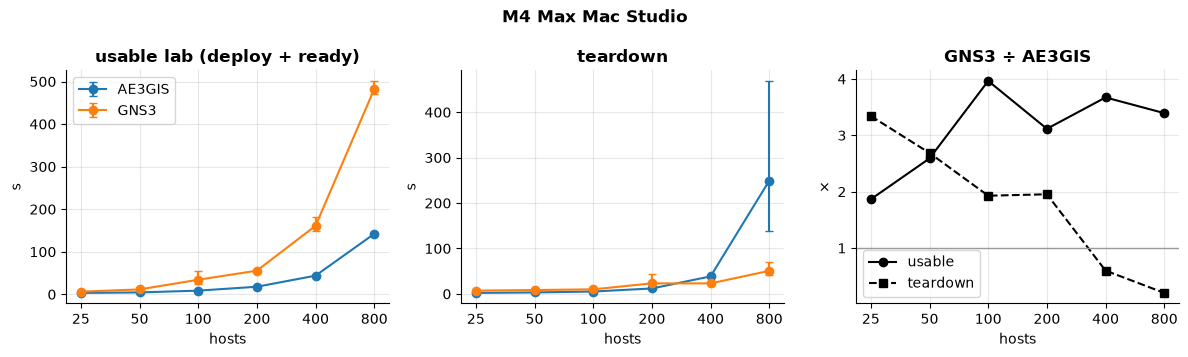

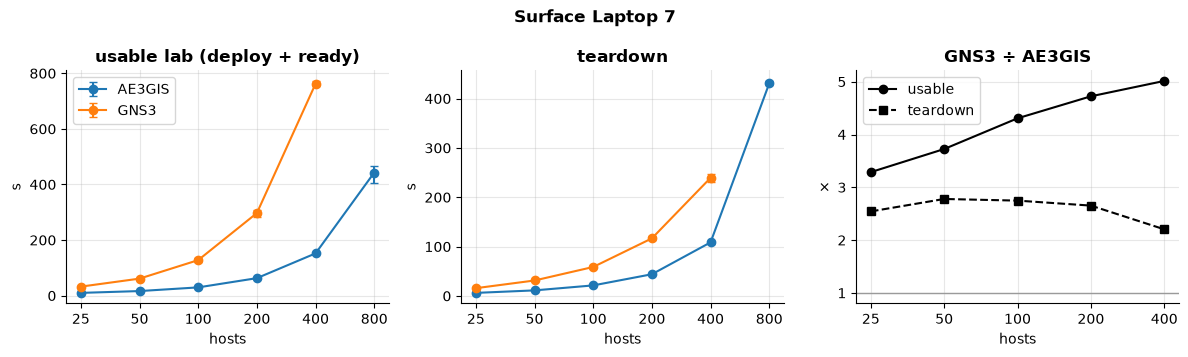

In [7]:
def by_size(ax, r, metric, scale=1.0, label=None):
    st = r.e1_stat(metric)
    for p in P:
        d = st[st.platform == p]
        if len(d):
            ax.errorbar(d["size"], d["mean"] * scale,
                        yerr=[(d["mean"] - d["min"]) * scale, (d["max"] - d["mean"]) * scale],
                        marker="o", capsize=3, color=C[p], label=N[p])
    ax.set_xscale("log", base=2)
    sizes = sorted(r.e1["size"].unique())
    ax.set_xticks(sizes, [str(s) for s in sizes])
    ax.set_xlabel("hosts")
    if label:
        ax.set_ylabel(label)

for h, r in R.items():
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
    by_size(ax[0], r, "usable_s", label="s"); ax[0].set_title("usable lab (deploy + ready)")
    by_size(ax[1], r, "teardown_s", label="s"); ax[1].set_title("teardown")
    q = r.ratio("usable_s"); t = r.ratio("teardown_s")
    ax[2].plot(q.index, q.values, marker="o", color="k", label="usable")
    ax[2].plot(t.index, t.values, marker="s", color="k", ls="--", label="teardown")
    ax[2].axhline(1, color=plots.GREY, lw=1)
    ax[2].set_xscale("log", base=2); ax[2].set_xticks(list(q.index), [str(s) for s in q.index])
    ax[2].set(title="GNS3 ÷ AE3GIS", xlabel="hosts", ylabel="×")
    ax[0].legend(); ax[2].legend()
    fig.suptitle(name(h), fontweight="bold"); fig.tight_layout(); plt.show()

    rows = r.e1.groupby(["size", "platform"]).agg(
        nodes=("nodes", "first"), reps=("rep", "count"),
        ok=("status", lambda s: int((s == "ok").sum())),
        statuses=("status", lambda s: ", ".join(sorted(set(s)))),
    ).join(r.e1_ok.groupby(["size", "platform"])[["deploy_s", "ready_s", "usable_s", "teardown_s"]].mean())
    display(rows.rename(index=N, level=1).style.format("{:.1f}", subset=["deploy_s", "ready_s", "usable_s", "teardown_s"], na_rep="–"))

## 4. E1: what a lab costs in memory

Over each step's reference, at the 60 s idle hold:
- **host footprint:** what the host gave the VM and its helpers;
- **VM memory:** `MemTotal − MemAvailable` inside the VM;
- **platform's own:** VM memory minus the lab's containers: Docker's shims, Kathara's VDE switches or GNS3's ubridge, …

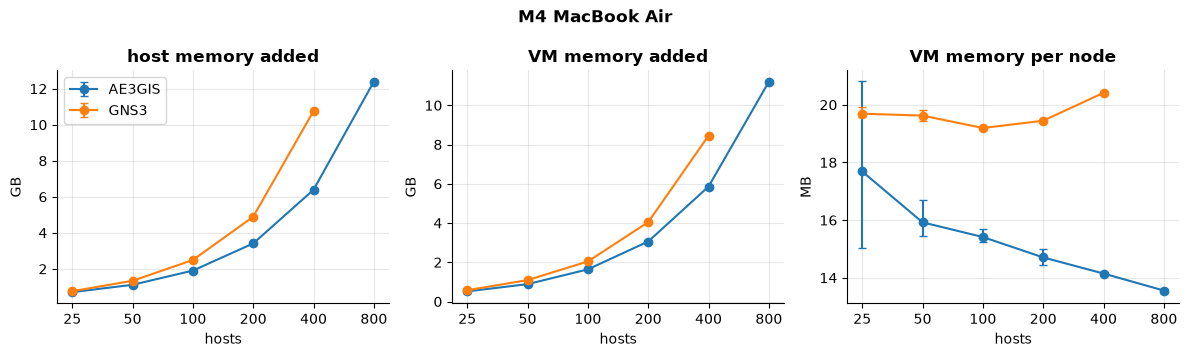

GNS3 ÷ AE3GIS

,host GB,VM GB,platform's own GB
size,,,
25,1.07×,1.11×,1.19×
50,1.20×,1.23×,1.28×
100,1.31×,1.25×,1.26×
200,1.43×,1.32×,1.33×
400,1.68×,1.44×,1.47×


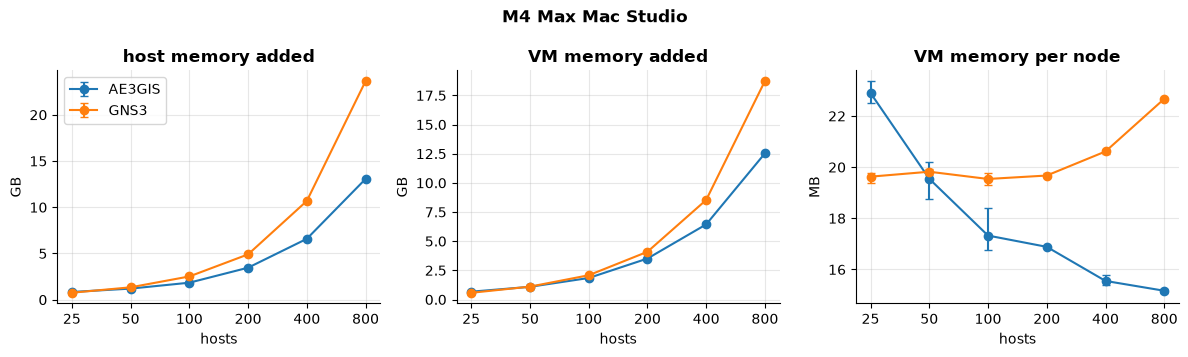

GNS3 ÷ AE3GIS

,host GB,VM GB,platform's own GB
size,,,
25,0.90×,0.86×,0.84×
50,1.12×,1.01×,1.00×
100,1.37×,1.13×,1.11×
200,1.42×,1.17×,1.14×
400,1.62×,1.33×,1.33×
800,1.81×,1.49×,1.53×


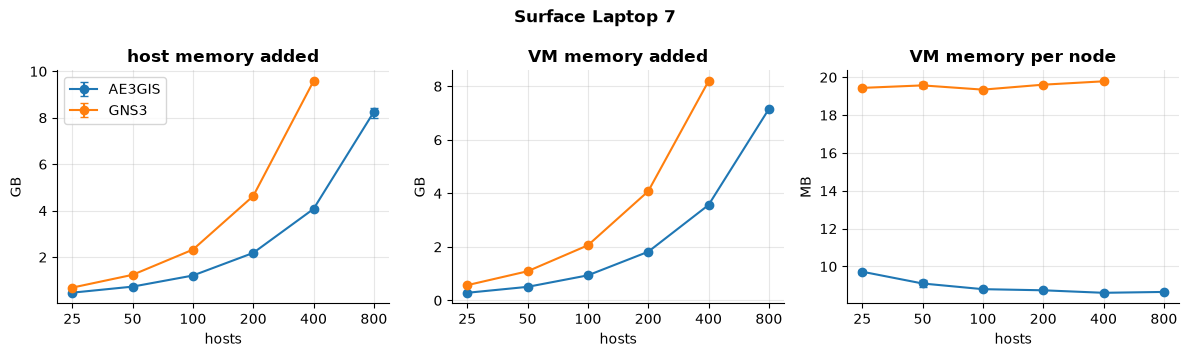

GNS3 ÷ AE3GIS

,host GB,VM GB,platform's own GB
size,,,
25,1.46×,2.00×,2.50×
50,1.70×,2.15×,2.63×
100,1.92×,2.20×,2.67×
200,2.12×,2.24×,2.70×
400,2.35×,2.30×,2.77×


In [8]:
for h, r in R.items():
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
    by_size(ax[0], r, "host_footprint_growth", 1 / GB, "GB"); ax[0].set_title("host memory added")
    by_size(ax[1], r, "vm_mem_growth", 1 / GB, "GB"); ax[1].set_title("VM memory added")
    by_size(ax[2], r, "vm_mem_per_node", 1 / MB, "MB"); ax[2].set_title("VM memory per node")
    ax[0].legend(); fig.suptitle(name(h), fontweight="bold"); fig.tight_layout(); plt.show()

    cols = {"host_footprint_growth": "host GB", "host_footprint_peak_growth": "host peak GB",
            "vm_mem_growth": "VM GB", "vm_mem_peak_growth": "VM peak GB",
            "platform_mem_growth": "platform's own GB", "vm_mem_after": "VM left after teardown GB"}
    t = r.e1_ok.groupby(["size", "platform"])[list(cols)].mean() / GB
    t["VM per node MB"] = r.e1_ok.groupby(["size", "platform"])["vm_mem_per_node"].mean() / MB
    display(t.rename(columns=cols).rename(index=N, level=1).style.format("{:.2f}"))
    ratios = pd.DataFrame({m: r.ratio(m) for m in ("host_footprint_growth", "vm_mem_growth", "platform_mem_growth")})
    if len(ratios):
        display(Markdown("GNS3 ÷ AE3GIS"))
        display(ratios.rename(columns=cols).style.format("{:.2f}×"))

In [9]:
# The lab's containers per role at hold (cgroup v2 vs v1: indicative only).
for h, r in R.items():
    if len(r.roles):
        t = r.roles.pivot_table(index=["role", "size"], columns="platform", values="mem_per_node") / MB
        display(Markdown(f"**{name(h)}**, MB per node"))
        display(t.rename(columns=N).style.format("{:.1f}"))

**M4 MacBook Air**, MB per node

**M4 Max Mac Studio**, MB per node

**Surface Laptop 7**, MB per node

## 5. E1: CPU with a lab up and idle

During the hold, nothing runs in the lab beyond each image's own services. Host cores are the VM process's and its helpers' CPU time on the Mac or PC; VM cores are the busy share of the VM's CPUs. A gap between the two is the hypervisor's own cost.

**AE3GIS's jump from 200 hosts up comes from Docker Desktop, not from the lab or AE3GIS.** In the table, the lab's containers stay near 0 cores; the CPU is `dockerd` and `containerd` (the platform's processes). Docker Desktop's UI process keeps running in the tray with its window closed. It re-lists every container once per container event, and with Docker Desktop's containerd image store each list gets slower as the containers add up. So a deploy leaves a backlog of lists that drains after it: about 80 s after a 200-host deploy on the M4 MacBook Air, and still going at the end of the hold at 400 and 800 hosts. Docker Desktop's API log shows the same calls (user agent `DockerDesktopUI`, one `GET /containers/json?all=true` per container created or removed). It's part of Docker Desktop's official setup, so it's counted as measured, but it's an aftermath of the deploy, not a steady cost of an idle lab: E3 below measures the lab once it's over. The same backlog adds to AE3GIS's CPU during the deploy.

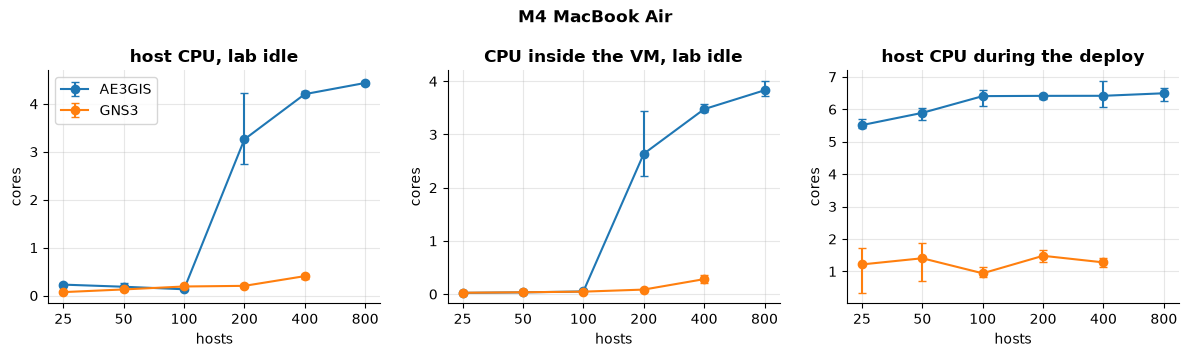

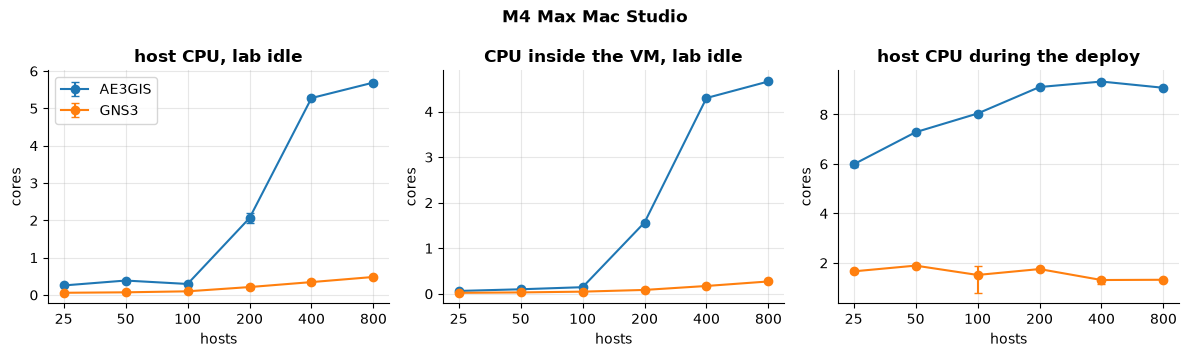

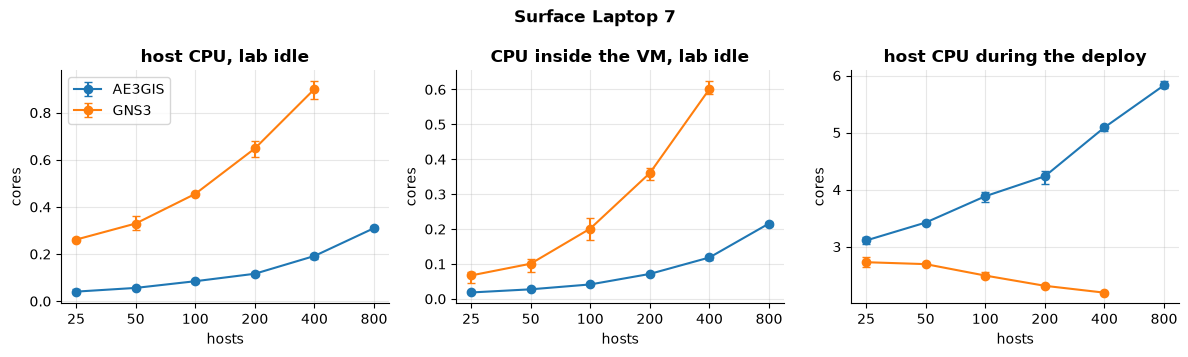

In [10]:
for h, r in R.items():
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
    by_size(ax[0], r, "host_cores_hold", label="cores"); ax[0].set_title("host CPU, lab idle")
    by_size(ax[1], r, "vm_cores_hold", label="cores"); ax[1].set_title("CPU inside the VM, lab idle")
    by_size(ax[2], r, "host_cores_deploy", label="cores"); ax[2].set_title("host CPU during the deploy")
    ax[0].legend(); fig.suptitle(name(h), fontweight="bold"); fig.tight_layout(); plt.show()
    cols = ["host_cores_ref", "host_cores_hold", "vm_cores_hold", "lab_cores_hold", "infra_cores_hold", "host_cores_deploy", "vm_cores_deploy"]
    display(r.e1_ok.groupby(["size", "platform"])[cols].mean().rename(index=N, level=1).style.format("{:.3f}"))

**E3: the same lab at rest, once the aftermath is over.** One more step per platform (400 hosts): its hold starts only once the VM's CPU has stayed under 10% for 30 s (at most 20 min after the network is ready), and lasts 2 min. *Quiet after* is the time from the deploy's end until then; a platform already quiet when the wait starts shows the procedure's floor (finding the containers, the readiness check and the 30 s settle). Next to it, E1's hold at the same size.

In [11]:
for h, r in R.items():
    e3, e1 = r.s.get("e3") or {}, r.s.get("e1") or {}
    rows = []
    for p in P:
        for size, c in sorted((e3.get(p) or {}).items()):
            if not c["ok"]:
                rows.append({"hosts": size, "platform": N[p], "status": "/".join(c["statuses"])})
                continue
            m = lambda k, c=c: c[k]["mean"]  # noqa: E731
            rows.append({
                "hosts": size, "platform": N[p], "status": "ok" + (" (wait capped)" if c["capped"] else ""),
                "quiet after the deploy, s": m("quiet_after_deploy_s"),
                "host cores": m("host_cores_hold"), "VM cores": m("vm_cores_hold"),
                "dockerd, containerd & co": m("infra_cores_hold"), "lab's containers": m("lab_cores_hold"),
                "E1 hold: host cores": ((e1.get(p) or {}).get(size) or {}).get("host_cores_hold", {}).get("mean"),
            })
    if not rows:
        continue
    display(Markdown(f"**{name(h)}**: E3"))
    df = pd.DataFrame(rows).set_index(["hosts", "platform"])
    display(df.style.format("{:.2f}", subset=[c for c in df.columns if c != "status"], na_rep="–"))

**M4 MacBook Air**: E3

**M4 Max Mac Studio**: E3

**Surface Laptop 7**: E3

## 6. E1: disk

In [12]:
for h, r in R.items():
    cols = {"vm_disk_growth": "VM disk file grew GB", "vm_disk_left": "left after teardown GB",
            "docker_disk_growth": "Docker's disk use inside GB"}
    t = r.e1_ok.groupby(["size", "platform"])[list(cols)].mean() / GB
    display(Markdown(f"**{name(h)}**"))
    display(t.rename(columns=cols).rename(index=N, level=1).style.format("{:.3f}"))

**M4 MacBook Air**

**M4 Max Mac Studio**

**Surface Laptop 7**

## 7. One step over time

The largest size both platforms finished, in each platform's first round that finished it: the VM's footprint on the host and the memory used inside it, with the phases shaded.

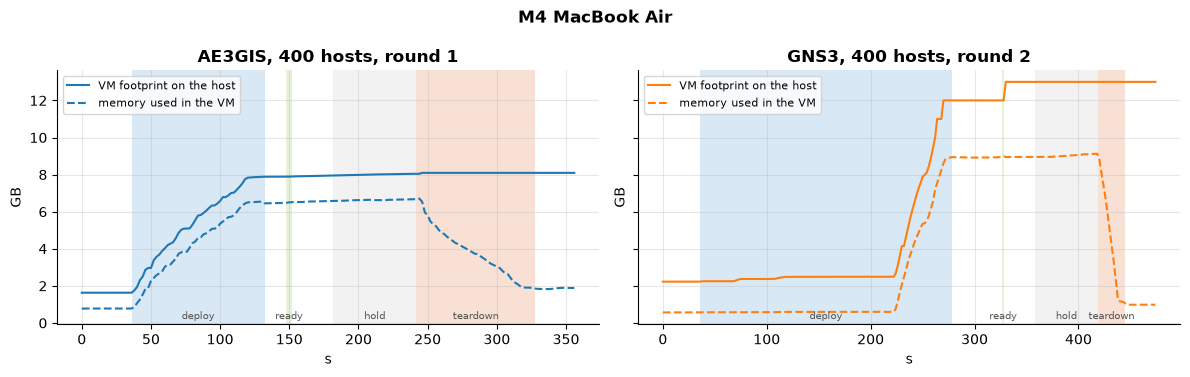

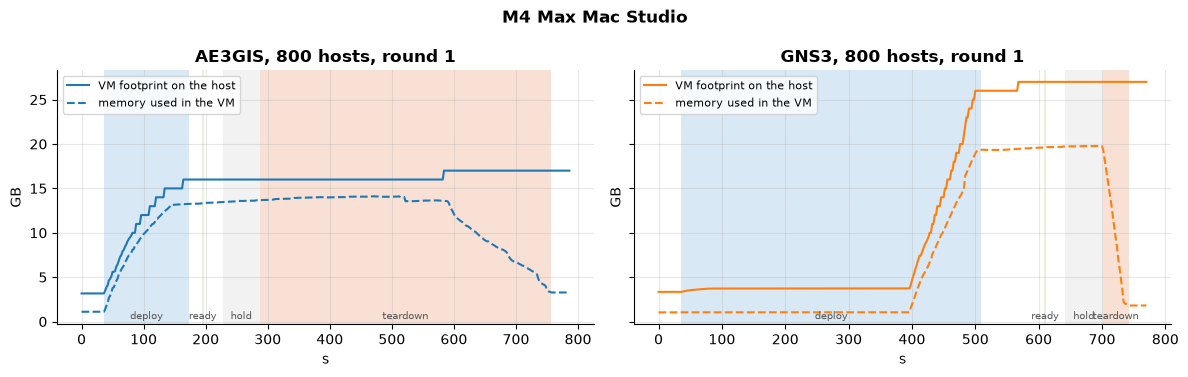

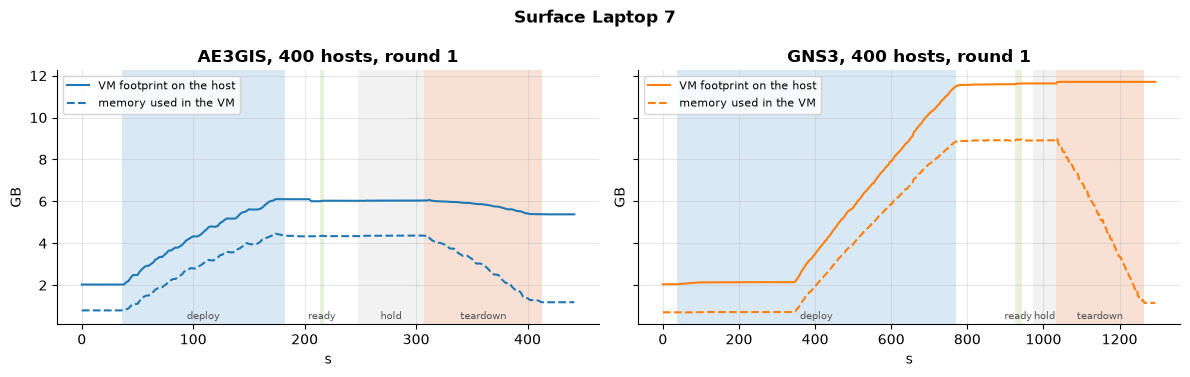

In [13]:
SHADE = {"deploy": "#d9e8f5", "ready": "#e6f2d9", "hold": "#f2f2f2", "teardown": "#f8e1d4"}
for h, r in R.items():
    ok = r.e1_ok.groupby("size")["platform"].nunique()
    both = [s for s, n in ok.items() if n == len(P)]
    if not both:
        continue
    n = max(both)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
    for a, p in zip(ax, P):
        reps = r.e1_ok[(r.e1_ok["platform"] == p) & (r.e1_ok["size"] == n)]["rep"]
        step = f"e1-h{n}-r{int(reps.min())}"
        d = r.series(p, step)
        if not len(d):
            continue
        for ph, (t0, t1) in r.phases(p, step).items():
            if ph in SHADE:
                a.axvspan(t0, t1, color=SHADE[ph], lw=0)
                a.text((t0 + t1) / 2, 0.01, ph, ha="center", va="bottom", fontsize=7, color="#555",
                       transform=a.get_xaxis_transform())
        a.plot(d["s"], d["footprint"] / GB, color=C[p], label="VM footprint on the host")
        a.plot(d["s"], d["vm_mem"] / GB, color=C[p], ls="--", label="memory used in the VM")
        a.set(title=f"{N[p]}, {n} hosts, round {int(reps.min())}", xlabel="s", ylabel="GB")
        a.legend(fontsize=8, loc="upper left")
    fig.suptitle(name(h), fontweight="bold"); fig.tight_layout(); plt.show()

## 8. E2: the network

On one 100-host lab, after a VM restart:
- **latency:** 10 same-LAN and 10 cross-core host pairs, 20 pings each;
- **flat-out:** one unpaced iperf3 TCP flow per pair kind, 3 trials;
- **load ladder:** clients → servers and mesh, TCP and UDP, every flow at a constant rate, stepped up until delivery falls under 95% or UDP loss passes 1% (the edge runs twice).

CPU per 100 Mb/s is over the lab's idle reference.

In [14]:
for h, r in R.items():
    display(Markdown(f"**{name(h)}**"))
    if len(r.latency):
        t = r.latency.set_index(["kind", "platform"])[["p50_ms", "p95_ms", "max_ms", "mean_ms", "replies", "sent"]]
        display(t.rename(index=N, level=1).style.format("{:.2f}", subset=["p50_ms", "p95_ms", "max_ms", "mean_ms"]))
    if len(r.flatout):
        t = r.flatout.groupby(["kind", "platform"])[["gbps", "host_cores", "vm_cores", "retransmits"]].mean()
        display(t.rename(index=N, level=1).style.format("{:.2f}"))

**M4 MacBook Air**

,,p50_ms,p95_ms,max_ms,mean_ms,replies,sent
kind,platform,,,,,,
cross_core,AE3GIS,6.55,9.15,10.09,5.96,200,200
same_lan,AE3GIS,1.52,3.48,10.62,1.85,200,200
cross_core,GNS3,1.35,1.74,2.15,1.14,200,200
same_lan,GNS3,0.44,0.89,1.20,0.48,200,200


**M4 Max Mac Studio**

,,p50_ms,p95_ms,max_ms,mean_ms,replies,sent
kind,platform,,,,,,
cross_core,AE3GIS,6.97,9.66,12.11,6.26,200,200
same_lan,AE3GIS,4.12,6.43,8.58,3.71,200,200
cross_core,GNS3,1.42,2.50,3.48,1.44,200,200
same_lan,GNS3,0.27,1.12,2.12,0.42,200,200


**Surface Laptop 7**

,,p50_ms,p95_ms,max_ms,mean_ms,replies,sent
kind,platform,,,,,,
cross_core,AE3GIS,2.54,4.97,9.15,2.91,200,200
same_lan,AE3GIS,1.22,3.14,61.36,3.01,200,200
cross_core,GNS3,13.60,34.08,49.31,15.05,200,200
same_lan,GNS3,1.47,15.06,51.04,3.77,200,200


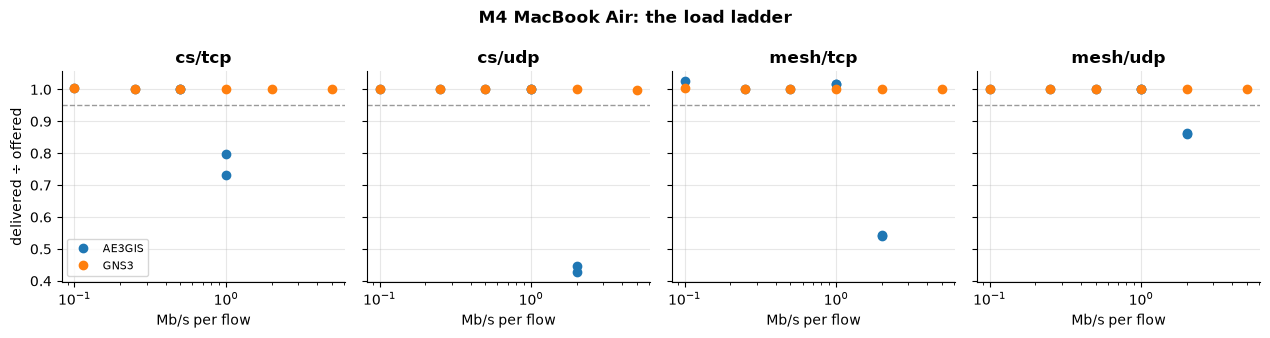

,,max_rate,flows,offered there Mb/s,peak delivered Mb/s
scenario,platform,,,,
cs/tcp,AE3GIS,500K,100,50,80
cs/udp,AE3GIS,1M,100,100,100
mesh/tcp,AE3GIS,1M,200,200,218
mesh/udp,AE3GIS,1M,200,200,346
cs/tcp,GNS3,5M,100,500,500
cs/udp,GNS3,5M,100,500,498
mesh/tcp,GNS3,5M,200,1000,1000
mesh/udp,GNS3,5M,200,1000,1000


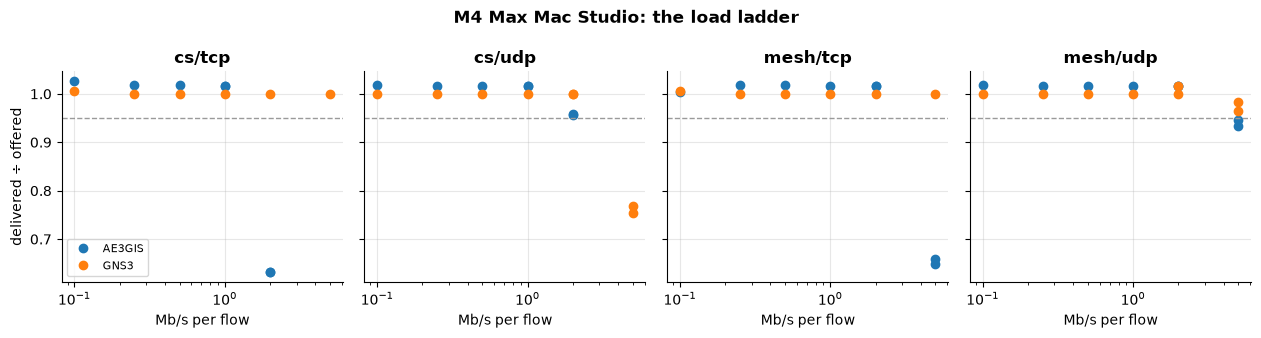

,,max_rate,flows,offered there Mb/s,peak delivered Mb/s
scenario,platform,,,,
cs/tcp,AE3GIS,1M,100,100,126
cs/udp,AE3GIS,1M,100,100,191
mesh/tcp,AE3GIS,2M,200,400,660
mesh/udp,AE3GIS,2M,200,400,946
cs/tcp,GNS3,5M,100,500,500
cs/udp,GNS3,2M,100,200,385
mesh/tcp,GNS3,5M,200,1000,1000
mesh/udp,GNS3,2M,200,400,983


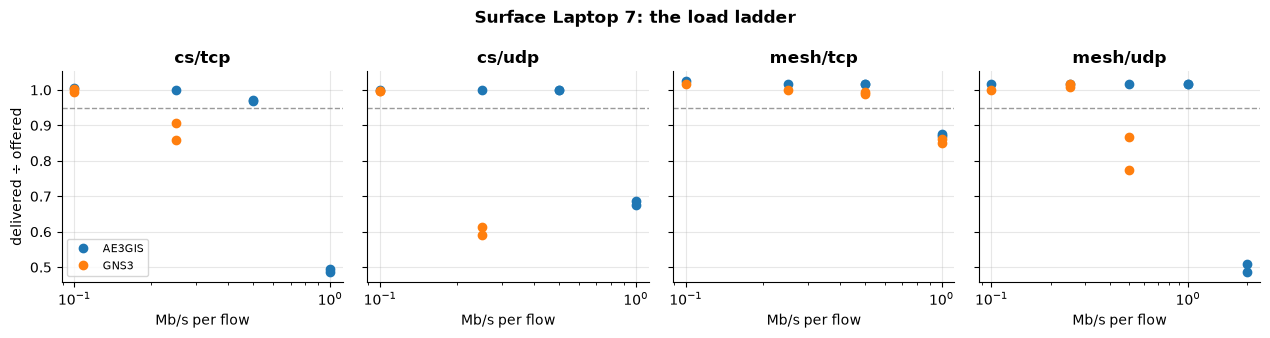

,,max_rate,flows,offered there Mb/s,peak delivered Mb/s
scenario,platform,,,,
cs/tcp,AE3GIS,500K,100,50,50
cs/udp,AE3GIS,500K,100,50,69
mesh/tcp,AE3GIS,500K,200,100,175
mesh/udp,AE3GIS,1M,200,200,203
cs/tcp,GNS3,100K,100,10,23
cs/udp,GNS3,100K,100,10,15
mesh/tcp,GNS3,500K,200,100,173
mesh/udp,GNS3,250K,200,50,87


In [15]:
for h, r in R.items():
    lad = r.ladder
    if not len(lad):
        continue
    scen = sorted(lad["scenario"].unique())
    fig, ax = plt.subplots(1, len(scen), figsize=(3.2 * len(scen), 3.4), sharey=True)
    ax = ax if len(scen) > 1 else [ax]
    for a, k in zip(ax, scen):
        for p in P:
            d = lad[(lad.scenario == k) & (lad.platform == p)].sort_values("rate_bps")
            if len(d):
                a.plot(d["rate_bps"] / 1e6, d["delivered_ratio"], marker="o", ls="", color=C[p], label=N[p])
        a.axhline(0.95, color=plots.GREY, lw=1, ls="--")
        a.set_xscale("log"); a.set(title=k, xlabel="Mb/s per flow")
    ax[0].set_ylabel("delivered ÷ offered"); ax[0].legend(fontsize=8)
    fig.suptitle(f"{name(h)}: the load ladder", fontweight="bold"); fig.tight_layout(); plt.show()

    best = r.ladder_best.set_index(["scenario", "platform"])[["max_rate", "flows", "max_offered_bps", "peak_delivered_bps"]]
    best["max_offered_bps"] /= 1e6; best["peak_delivered_bps"] /= 1e6
    display(best.rename(columns={"max_offered_bps": "offered there Mb/s", "peak_delivered_bps": "peak delivered Mb/s"})
            .rename(index=N, level=1).style.format("{:.0f}", subset=["offered there Mb/s", "peak delivered Mb/s"], na_rep="–"))

In [16]:
# CPU at the same load: each scenario at every rate both platforms passed (first runs).
for h, r in R.items():
    lad = r.ladder[~r.ladder["repeat"] & r.ladder["passed"]]
    if not len(lad):
        continue
    t = lad.pivot_table(index=["scenario", "rate_bps"], columns="platform", values="host_cores_per_100m").dropna()
    if not len(t):
        continue
    t.index = t.index.set_levels([f"{x / 1e6:g}M" for x in t.index.levels[1]], level=1)
    t = t.rename(columns=N)
    t["GNS3 ÷ AE3GIS"] = t["GNS3"] / t["AE3GIS"]
    display(Markdown(f"**{name(h)}**: host cores per 100 Mb/s delivered"))
    display(t.style.format("{:.3f}"))

**M4 MacBook Air**: host cores per 100 Mb/s delivered

**M4 Max Mac Studio**: host cores per 100 Mb/s delivered

**Surface Laptop 7**: host cores per 100 Mb/s delivered

## 9. Takeaways

In [17]:
def x(v, nd=2):
    return "–" if v is None or pd.isna(v) else f"{v:.{nd}f}"

for h, r in R.items():
    out = [f"**{name(h)}**", ""]
    e0 = r.s["e0"]["mean"]
    a, g = e0.get("ae3gis"), e0.get("gns3")
    if a and g:
        out.append(
            f"- **At rest:** AE3GIS takes {x(a['host_footprint'] / GB)} GB of the host's memory "
            f"({x(a['host_footprint_helpers'] / GB)} GB of it Docker Desktop's helpers), GNS3 "
            f"{x(g['host_footprint'] / GB)} GB; inside the VMs, {x(a['vm_mem'] / GB)} vs "
            f"{x(g['vm_mem'] / GB)} GB. Host CPU at rest: {x(a['host_cores'], 3)} vs {x(g['host_cores'], 3)} cores."
        )
    sizes = {p: sorted(r.e1_ok[r.e1_ok.platform == p]["size"].unique()) for p in P}
    out.append("- **Largest lab finished:** " + ", ".join(
        f"{N[p]} {max(s) if s else 'none'} hosts" for p, s in sizes.items()))
    ok = r.e1_ok.groupby("size")["platform"].nunique()
    both = [s for s, n in ok.items() if n == len(P)]
    if both:
        n = max(both)
        m = r.e1_ok[r.e1_ok["size"] == n].groupby("platform").mean(numeric_only=True)
        def pair(metric, scale=1.0, nd=1, unit=""):
            return (f"{x(m.loc['ae3gis', metric] * scale, nd)}{unit} vs {x(m.loc['gns3', metric] * scale, nd)}{unit} "
                    f"({x(r.ratio(metric).get(n))}×)")
        out += [
            f"- **At {n} hosts** (AE3GIS vs GNS3, then GNS3 ÷ AE3GIS):",
            f"  - usable lab: {pair('usable_s', unit=' s')}; teardown: {pair('teardown_s', unit=' s')};",
            f"  - host memory added: {pair('host_footprint_growth', 1 / GB, 2, ' GB')}; VM memory added: "
            f"{pair('vm_mem_growth', 1 / GB, 2, ' GB')};",
            f"  - host CPU with the lab idle: {pair('host_cores_hold', nd=2, unit=' cores')}; of it, `dockerd`, "
            f"`containerd` and the like inside the VM: {x(m.loc['ae3gis', 'infra_cores_hold'], 2)} vs "
            f"{x(m.loc['gns3', 'infra_cores_hold'], 2)} cores (section 5 says why).",
        ]
    e3 = r.s.get("e3") or {}
    for size in sorted({n for c in e3.values() for n in c}):
        c = {p: (e3.get(p) or {}).get(size) for p in P}
        if all(v and v["ok"] for v in c.values()):
            q = lambda p, k: c[p][k]["mean"]  # noqa: E731
            out.append(
                f"- **At rest once the deploy's aftermath is over (E3, {size} hosts):** host CPU "
                f"{x(q('ae3gis', 'host_cores_hold'))} vs {x(q('gns3', 'host_cores_hold'))} cores, reached "
                f"{x(q('ae3gis', 'quiet_after_deploy_s'), 0)} s vs {x(q('gns3', 'quiet_after_deploy_s'), 0)} s "
                f"after the deploy" + (" (a wait was capped)" if any(v["capped"] for v in c.values()) else "") + ".")
    e2 = r.s["e2"]
    if len(e2) == len(P):
        lat = r.latency.set_index(["kind", "platform"])
        for k in sorted(r.latency["kind"].unique()):
            out.append(f"- **Ping {k}:** p50 {x(lat.loc[(k, 'ae3gis'), 'p50_ms'])} vs "
                       f"{x(lat.loc[(k, 'gns3'), 'p50_ms'])} ms, p95 {x(lat.loc[(k, 'ae3gis'), 'p95_ms'])} vs "
                       f"{x(lat.loc[(k, 'gns3'), 'p95_ms'])} ms.")
        if len(r.flatout):
            fo = r.flatout.groupby(["kind", "platform"])["gbps"].mean()
            out.append("- **One flat-out TCP flow:** " + "; ".join(
                f"{k} {x(fo.get((k, 'ae3gis')))} vs {x(fo.get((k, 'gns3')))} Gb/s"
                for k in sorted(r.flatout["kind"].unique())) + ".")
        best = r.ladder_best.set_index(["scenario", "platform"])["max_rate"]
        rate = lambda k, p: best.get((k, p)) if isinstance(best.get((k, p)), str) else "none"  # noqa: E731
        out.append("- **Highest rate per flow passed:** " + "; ".join(
            f"{k} {rate(k, 'ae3gis')} vs {rate(k, 'gns3')}"
            for k in sorted(r.ladder_best["scenario"].unique())) + ".")
    display(Markdown("\n".join(out)))

**M4 MacBook Air**

- **At rest:** AE3GIS takes 2.09 GB of the host's memory (0.45 GB of it Docker Desktop's helpers), GNS3 2.25 GB; inside the VMs, 0.78 vs 0.57 GB. Host CPU at rest: 0.045 vs 0.033 cores.
- **Largest lab finished:** AE3GIS 800 hosts, GNS3 400 hosts
- **At 400 hosts** (AE3GIS vs GNS3, then GNS3 ÷ AE3GIS):
  - usable lab: 90.6 s vs 209.6 s (2.31×); teardown: 73.8 s vs 74.1 s (1.00×);
  - host memory added: 6.39 GB vs 10.76 GB (1.68×); VM memory added: 5.86 GB vs 8.45 GB (1.44×);
  - host CPU with the lab idle: 4.20 cores vs 0.41 cores (0.10×); of it, `dockerd`, `containerd` and the like inside the VM: 3.36 vs 0.16 cores (section 5 says why).
- **At rest once the deploy's aftermath is over (E3, 400 hosts):** host CPU 0.24 vs 0.26 cores, reached 337 s vs 79 s after the deploy.
- **Ping cross_core:** p50 6.55 vs 1.35 ms, p95 9.15 vs 1.74 ms.
- **Ping same_lan:** p50 1.52 vs 0.44 ms, p95 3.48 vs 0.89 ms.
- **One flat-out TCP flow:** cross_core 0.08 vs 1.59 Gb/s; same_lan 0.13 vs 4.65 Gb/s.
- **Highest rate per flow passed:** cs/tcp 500K vs 5M; cs/udp 1M vs 5M; mesh/tcp 1M vs 5M; mesh/udp 1M vs 5M.

**M4 Max Mac Studio**

- **At rest:** AE3GIS takes 3.81 GB of the host's memory (0.62 GB of it Docker Desktop's helpers), GNS3 3.35 GB; inside the VMs, 1.13 vs 1.02 GB. Host CPU at rest: 0.058 vs 0.032 cores.
- **Largest lab finished:** AE3GIS 800 hosts, GNS3 800 hosts
- **At 800 hosts** (AE3GIS vs GNS3, then GNS3 ÷ AE3GIS):
  - usable lab: 142.1 s vs 482.4 s (3.39×); teardown: 249.3 s vs 50.7 s (0.20×);
  - host memory added: 13.06 GB vs 23.64 GB (1.81×); VM memory added: 12.53 GB vs 18.73 GB (1.49×);
  - host CPU with the lab idle: 5.69 cores vs 0.48 cores (0.08×); of it, `dockerd`, `containerd` and the like inside the VM: 4.33 vs 0.13 cores (section 5 says why).
- **At rest once the deploy's aftermath is over (E3, 400 hosts):** host CPU 0.83 vs 0.26 cores, reached 1244 s vs 82 s after the deploy (a wait was capped).
- **Ping cross_core:** p50 6.97 vs 1.42 ms, p95 9.66 vs 2.50 ms.
- **Ping same_lan:** p50 4.12 vs 0.27 ms, p95 6.43 vs 1.12 ms.
- **One flat-out TCP flow:** cross_core 0.12 vs 2.23 Gb/s; same_lan 0.12 vs 5.53 Gb/s.
- **Highest rate per flow passed:** cs/tcp 1M vs 5M; cs/udp 1M vs 2M; mesh/tcp 2M vs 5M; mesh/udp 2M vs 2M.

**Surface Laptop 7**

- **At rest:** AE3GIS takes 2.92 GB of the host's memory (0.88 GB of it Docker Desktop's helpers), GNS3 2.25 GB; inside the VMs, 0.78 vs 0.72 GB. Host CPU at rest: 0.028 vs 0.187 cores.
- **Largest lab finished:** AE3GIS 800 hosts, GNS3 400 hosts
- **At 400 hosts** (AE3GIS vs GNS3, then GNS3 ÷ AE3GIS):
  - usable lab: 152.1 s vs 762.5 s (5.01×); teardown: 108.6 s vs 239.4 s (2.20×);
  - host memory added: 4.07 GB vs 9.58 GB (2.35×); VM memory added: 3.56 GB vs 8.19 GB (2.30×);
  - host CPU with the lab idle: 0.19 cores vs 0.90 cores (4.69×); of it, `dockerd`, `containerd` and the like inside the VM: 0.07 vs 0.40 cores (section 5 says why).
- **At rest once the deploy's aftermath is over (E3, 400 hosts):** host CPU 0.18 vs 0.89 cores, reached 66 s vs 446 s after the deploy.
- **Ping cross_core:** p50 2.54 vs 13.60 ms, p95 4.97 vs 34.08 ms.
- **Ping same_lan:** p50 1.22 vs 1.47 ms, p95 3.14 vs 15.06 ms.
- **One flat-out TCP flow:** cross_core 0.05 vs 0.08 Gb/s; same_lan 0.02 vs 0.48 Gb/s.
- **Highest rate per flow passed:** cs/tcp 500K vs 100K; cs/udp 500K vs 100K; mesh/tcp 500K vs 500K; mesh/udp 1M vs 250K.

## 10. Across machines

The headline ratios (GNS3 ÷ AE3GIS) on every machine that ran the comparison, at the largest size both platforms finished there.

In [18]:
rows = []
for h, r in R.items():
    ok = r.e1_ok.groupby("size")["platform"].nunique()
    both = [s for s, n in ok.items() if n == len(P)]
    if not both:
        continue
    n = max(both)
    e0 = r.s["e0"]["mean"]
    rows.append({
        "host": name(h), "hosts": n,
        "at rest: host memory": (e0.get("gns3", {}).get("host_footprint") or 0) / (e0.get("ae3gis", {}).get("host_footprint") or float("nan")),
        **{lbl: r.ratio(m).get(n) for m, lbl in [
            ("usable_s", "usable"), ("teardown_s", "teardown"),
            ("host_footprint_growth", "host memory added"), ("vm_mem_growth", "VM memory added"),
            ("host_cores_hold", "host CPU, lab idle")]},
    })
if rows:
    display(pd.DataFrame(rows).set_index("host").style.format("{:.2f}", subset=pd.IndexSlice[:, [c for c in rows[0] if c not in ("host", "hosts")]]))

,hosts,at rest: host memory,usable,teardown,host memory added,VM memory added,"host CPU, lab idle"
host,,,,,,,
M4 MacBook Air,400,1.08,2.31,1.00,1.68,1.44,0.10
M4 Max Mac Studio,800,0.88,3.39,0.20,1.81,1.49,0.08
Surface Laptop 7,400,0.77,5.01,2.20,2.35,2.30,4.69
